# Task 3: Data analysis of personalized vs. random video exposure (KuaiRand-1K)

**Question.** Is personalized exposure associated with a higher share of completed views than random exposure?

This notebook follows the Task 3 structure:

1. Data ingestion and cleaning (the analog of *warm-up filtering*),
2. Statistical aggregation (median, p95, p99, 95% bootstrap CI, Mean ± SD),
3. Visualization and export to `reports/figures/`.

The reusable logic lives in `src/process_data.py` and `src/visualize.py`; the notebook only calls it and explains the results.
Run it with **Kernel → Restart & Run All** from the repository root's `notebooks/` folder. The random seed is fixed to 42.

In [1]:
import os, sys
from pathlib import Path

# make the notebook work no matter where Jupyter was started
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

import process_data as pdt
import visualize as viz

SEED = 42
np.random.seed(SEED)  # global seed; the bootstrap itself uses numpy.random.default_rng(SEED)

CONFIG = os.environ.get("TASK3_CONFIG", "configs/config.yaml")
cfg = yaml.safe_load(open(CONFIG, encoding="utf-8"))
assert cfg["processing"]["seed"] == SEED
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("Config:", CONFIG, "| mode:", cfg["project"]["mode"], "| seed:", SEED)

Config: configs/config.yaml | mode: full | seed: 42


## 1. Data ingestion and cleaning

This study has no latency benchmark, so there is no cold-start warm-up phase. The analog is the cleaning step:

- load the personalized log (`is_rand = 0`) and the random log (`is_rand = 1`) for the same period 22.04–08.05.2022;
- drop views with missing values, `duration_ms <= 0` or `play_time_ms < 0`;
- **count** every removed row and report it as a guardrail metric (instead of silently dropping it, to avoid selection bias).

A view is *completed* if `play_time_ms >= 0.9 * duration_ms`.

In [2]:
df, quality = pdt.load_views(cfg)
print(f"Clean views: {len(df):,}")
quality

Clean views: 6,171,574


,group,n_raw,n_missing,n_invalid,n_clean,invalid_share_pct
0,Personalized,6657061,0,527205,6129856,7.919486
1,Random (baseline),43028,0,1310,41718,3.044529


In [3]:
# Guardrail G1: enough observations in each group
print(df.groupby("group").size().rename("views").to_frame().assign(ok=lambda t: t["views"] >= cfg["guardrails"]["min_obs_per_group"]))

                     views    ok
group                           
Personalized       6129856  True
Random (baseline)    41718  True


### Outliers (non-destructive flag)

Watch time is heavily right-skewed. Very long views are real behavior, not hardware noise, so we only **flag** them with the 1.5·IQR rule and keep them in all statistics.

In [4]:
flag = df.groupby("group")["watch_time_s"].apply(lambda s: pdt.iqr_outlier_flag(s.to_numpy()).mean() * 100)
flag.rename("flagged_by_IQR_rule_%").round(2).to_frame()

,flagged_by_IQR_rule_%
group,
Personalized,12.64
Random (baseline),13.32


## 2. Statistical aggregation

For every group we compute completion rate with a 95% **cluster bootstrap** CI (whole users are resampled, because views of one user are not independent),
watch time as Mean ± SD and Median (p25–p75), and p95 / p99 with 95% bootstrap CIs. The same is done for each recommendation scenario (`tab`).
Because the distribution is skewed, the median and percentiles are more informative than the mean.

In [5]:
summary = pdt.build_summary(df, quality, cfg)
groups = summary[summary["scope"].isin(["group", "difference"])].dropna(axis=1, how="all")
groups.set_index("group").T

group,Personalized,Random (baseline),Personalized - Random
scope,group,group,difference
n_views,6129856,41718,6171574
n_users,1000.0,1000.0,NaN
completion_rate_pct,19.353522,4.084568,15.268954
cr_ci_low_pct,18.409506,3.713135,14.270112
cr_ci_high_pct,20.324039,4.456399,16.315632
watch_mean_s,15.380082,6.847575,NaN
watch_sd_s,35.263217,18.005883,NaN
watch_median_s,3.211,2.104,NaN
watch_median_ci_low_s,3.159,2.085,NaN


In [6]:
model = pdt.load_model_summary(Path(cfg["output"]["dir"]) / f"results_{cfg['project']['mode']}.json")
table_md = pdt.results_table_md(summary, quality, model)
print(table_md)

| Metric | Baseline: Random exposure | Proposed: Personalized exposure |
|---|---|---|
| Views after cleaning (n) | 41,718 | 6,129,856 |
| Users (n) | 1,000 | 1,000 |
| Completion rate, % [95% bootstrap CI] | 4.08 [3.71, 4.46] | 19.35 [18.41, 20.32] |
| Watch time, s: Mean ± SD | 6.85 ± 18.01 | 15.38 ± 35.26 |
| Watch time, s: Median (p25–p75) | 2.10 (1.33–4.62) | 3.21 (1.08–13.27) |
| Watch time p95, s [95% CI] | 27.53 [26.38, 28.72] | 73.81 [72.79, 77.09] |
| Watch time p99, s [95% CI] | 89.64 [85.62, 93.30] | 173.50 [166.63, 178.56] |
| Guardrail: invalid/missing rows, % | 3.04 | 7.92 |

Difference in completion rate (Personalized − Random): **15.27 p.p.** (95% bootstrap CI [14.27, 16.32]).

Adjusted odds ratio of completion (logistic regression, cluster-robust SE): **OR = 6.022**, 95% CI [5.200, 6.974], one-sided p = 2.527e-127.


The logistic-regression result (adjusted odds ratio) comes from `src/main.py` (`outputs/results_full.json`).
If it is not shown above, run `python src/main.py --config configs/config.yaml` first and re-run this notebook.

Exporting the processed files (small, tracked in git):

In [7]:
out = Path(cfg["processing"]["out_dir"]); out.mkdir(parents=True, exist_ok=True)
sample = pdt.make_plot_sample(df, cfg)
summary.to_csv(out / "metrics_summary.csv", index=False)
quality.to_csv(out / "data_quality.csv", index=False)
sample.to_csv(out / "watch_time_sample.csv", index=False)
if model:
    import json; (out / "model_summary.json").write_text(json.dumps(model, indent=2), encoding="utf-8")
print("Saved to", out, "->", sorted(p.name for p in out.iterdir()))

Saved to data\processed -> ['data_quality.csv', 'metrics_summary.csv', 'model_summary.json', 'watch_time_sample.csv']


## 3. Visualization and export

Both figures follow the three rules of scientific graphics: axes with names and units (log scale for values that span orders of magnitude),
95% CI shown, colorblind-safe palette with different markers / line styles / hatching. They are saved as vector `.pdf` and 300 DPI `.png`.

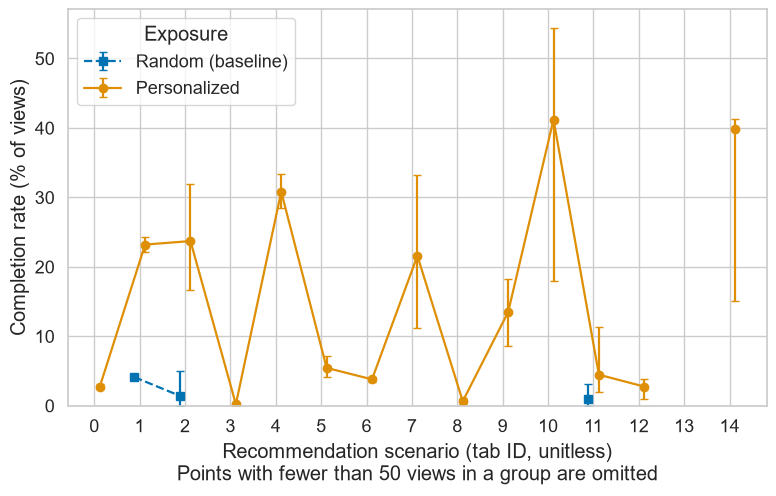

In [8]:
fig1 = viz.fig1_completion_by_tab(summary)
viz.save(fig1, "fig1_latency_vs_load", cfg["processing"]["figures_dir"])
plt.show()

**Figure 1.** Completion rate (% of views completed) per recommendation scenario for random (baseline, dashed, squares) and personalized exposure (solid, circles).
Error bars show the 95% bootstrap CI (users resampled). Scenarios with fewer than 50 views in a group are omitted and the line is broken there: random exposure appears almost only in scenario 1, so most scenarios cannot be compared between groups.

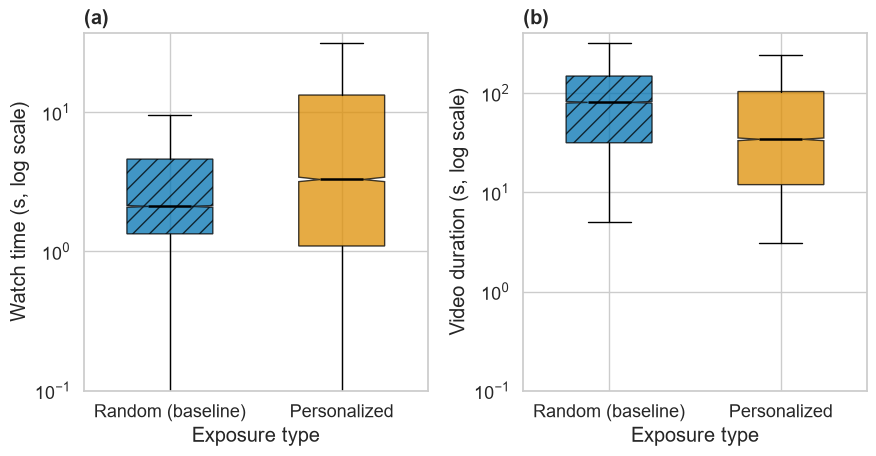

In [9]:
fig2 = viz.fig2_distribution_boxplot(sample, SEED, cfg["processing"]["n_boot"])
viz.save(fig2, "fig2_distribution_boxplot", cfg["processing"]["figures_dir"])
plt.show()

**Figure 2.** Distribution of (a) watch time and (b) video duration by exposure type, log scale. Boxes show p25–p75, the line is the median,
the notch is the 95% bootstrap CI of the median, whiskers extend to 1.5·IQR; outliers are not drawn. Computed on a seeded sample of at most 20 000 views per group.
Panel (b) matters for interpretation: if the two groups differ in video duration, the raw completion rates are not directly comparable, which is why the regression controls for `log(duration)`.

In [10]:
figdir = Path(cfg["processing"]["figures_dir"])
print(sorted(p.name for p in figdir.iterdir()))

['fig1_latency_vs_load.pdf', 'fig1_latency_vs_load.png', 'fig2_distribution_boxplot.pdf', 'fig2_distribution_boxplot.png']


## Discussion and limitations

- Read the numbers from the table above. A difference in completion rate is an **association**, not proof that personalization causes longer attention (the study is observational).
- Bootstrap CIs for the quantiles resample views, not users, and use a seeded sample of up to 50 000 views per group, so they are somewhat too narrow.
- Random exposure uses a small pool of videos (7 388 in KuaiRand-1K), so the groups can differ in video type and duration; see panel (b) of Figure 2.
- Completion is an engagement signal and does not necessarily mean user satisfaction.